# Loop Score Components

We look at the raw loop components (land use diversity, POI diversity and landscape attractiveness) before computing the loop score. Loop components come from each loop's own corridor, so we check how they're distributed, how they compare with the link components, how they relate to each other, and how they depend on loop length.

The goal is to check the expectations from link level and settle open choices for the loop score:
- whether POI saturates, and whether its definition (0–3 categories) still works at loop level
- whether land use diversity moves up and narrows compared with links
- how strongly the components depend on loop length
- whether the main specification (z-scores, 0.5 / 0.25 / 0.25) still gives weights that mean what they say

<br><br>

## 0. Setup

### 0.1. Imports and Config

In [14]:
import numpy as np
import pandas as pd

from splendor.config import (
    CORRIDOR_RADIUS,
    ROAD_STRIP_RADIUS,
    STUDY_AREA,
    SEED,
    DIVERSITY_MEASURES,
    EXCLUDED_TYPES,
    RICHNESS_MIN_SHARE,
    NORMALIZATION_METHODS,
    NORMALIZATION_PERCENTILE,
    POI_BOUNDS,
    ATTRACTIVENESS,
    MAIN_SPECIFICATION,
)
from splendor.io import load_network, load_raster
from splendor.landuse.types import N_TYPES
from splendor.paths import (
    network_path,
    basemap05_main_types_path,
    landuse_path,
    components_path,
    loop_attributes_path,
)
from splendor.plotting.charts import plot_counts, plot_distributions, plot_against, plot_scatter_matrix
from splendor.components.diversity import get_bounds
from splendor.composite.normalize import normalize_all

LEVEL = "loops"
ID_COLUMN = "loop_id"
K = N_TYPES - len(EXCLUDED_TYPES) # Land use types the measures see
SAMPLE_SIZE = 5000 # Loops shown in scatter plots (all loops would overplot)
THEORETICAL_MAX = { # Reference lines only
    "shannon": np.log(K),
    "inverse_simpson": K,
    "richness": min(K, int(1 / RICHNESS_MIN_SHARE)), # At most 1 / threshold types can reach the threshold
}
TITLES = (
    {m: m.replace("_", " ").capitalize() for m in DIVERSITY_MEASURES} |
    {"poi": "POI", "attractiveness": "Landscape attractiveness"}
)

measure_columns = [f"diversity_{m}" for m in DIVERSITY_MEASURES]
component_columns = [*measure_columns, "poi_diversity", "attractiveness"]
component_titles = [TITLES[m] for m in DIVERSITY_MEASURES] + [TITLES["poi"], TITLES["attractiveness"]]

bounds = {f"diversity_{m}": get_bounds(m, K, RICHNESS_MIN_SHARE) for m in DIVERSITY_MEASURES}
bounds["poi_diversity"] = POI_BOUNDS
bounds["attractiveness"] = (min(ATTRACTIVENESS.values()), max(ATTRACTIVENESS.values()))

### 0.2. Data

In [15]:
path_args = (STUDY_AREA, LEVEL, CORRIDOR_RADIUS, ROAD_STRIP_RADIUS)

loop_components = pd.read_csv(components_path(*path_args), index_col=ID_COLUMN)
attributes = pd.read_csv(loop_attributes_path(STUDY_AREA), index_col=ID_COLUMN)
loop_landuse = pd.read_csv(landuse_path(*path_args), index_col=ID_COLUMN, usecols=[ID_COLUMN, "n_pixels", "n_excluded"])
loops = loop_components.join(attributes, how="inner").join(loop_landuse, how="inner")
loops_sample = loops.sample(SAMPLE_SIZE, random_state=SEED)

# Links for comparison
_, edges = load_network(network_path(STUDY_AREA))
link_components = pd.read_csv(components_path(STUDY_AREA, "links", CORRIDOR_RADIUS, ROAD_STRIP_RADIUS), index_col="edge_id")
links = link_components.join(edges.set_index("edge_id")[["length_m", "poi_diversity"]], how="inner")
assert len(links) == len(edges) == len(link_components), "edge ids of network and components file don't match"


def compare_levels(column: str) -> pd.DataFrame:
    """Summary statistics of a column for links and loops, side by side."""
    return pd.DataFrame({"links": links[column].describe(), "loops": loops[column].describe()}).round(3)


print(loops[["length_m", "n_nodes", *component_columns]].describe().round(3))

        length_m    n_nodes  diversity_shannon  diversity_richness  \
count  45218.000  45218.000          45218.000           45218.000   
mean   35608.250     20.222              1.114               2.322   
std     4575.005      3.772              0.212               0.609   
min     2804.113      3.000              0.491               1.000   
25%    33983.006     18.000              0.953               2.000   
50%    37061.970     21.000              1.105               2.000   
75%    38789.765     23.000              1.274               3.000   
max    39999.946     30.000              1.910               5.000   

       poi_diversity  attractiveness  
count      45218.000       45218.000  
mean           2.867           0.236  
std            0.384           0.024  
min            0.000           0.036  
25%            3.000           0.222  
50%            3.000           0.236  
75%            3.000           0.250  
max            3.000           0.525  


<br><br>

## 1. Sanity Checks

In [16]:
# The joins above are inner joins, so mismatching loop ids would silently drop rows
assert len(loops) == len(loop_components) == len(attributes) == len(loop_landuse), "loop ids of the loop files don't match"
assert (loops.index.to_numpy() == np.arange(len(loops))).all(), "loop ids not 0..n-1"
assert not loops[component_columns].isna().any().any(), "missing component values"

for column in component_columns:
    lo, hi = bounds[column]
    assert loops[column].between(lo, hi).all(), f"{column} outside its bounds ({lo}, {hi})"

print(f"{len(loops)} loops, all checks passed")

45218 loops, all checks passed


<br><br>

## 2. POI Diversity

               links  loops
poi_diversity              
0              0.387  0.000
1              0.342  0.015
2              0.177  0.102
3              0.094  0.882


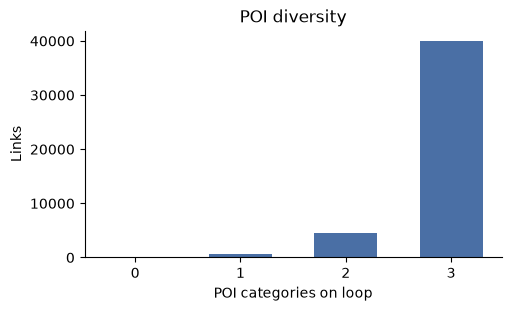

In [17]:
poi_shares = pd.DataFrame({
    "links": links["poi_diversity"].value_counts(normalize=True).reindex(range(4), fill_value=0),
    "loops": loops["poi_diversity"].value_counts(normalize=True).reindex(range(4), fill_value=0),
}).round(3)
print(poi_shares)

plot_counts(loops, "poi_diversity", range(4), "POI diversity", "POI categories on loop");

<br><br>

## 3. Land Use Diversity

diversity_shannon
         links      loops
count  638.000  45218.000
mean     0.857      1.114
std      0.337      0.212
min      0.081      0.491
25%      0.612      0.953
50%      0.804      1.105
75%      1.080      1.274
max      1.931      1.910

diversity_richness
         links      loops
count  638.000  45218.000
mean     2.011      2.322
std      0.773      0.609
min      1.000      1.000
25%      2.000      2.000
50%      2.000      2.000
75%      2.000      3.000
max      5.000      5.000



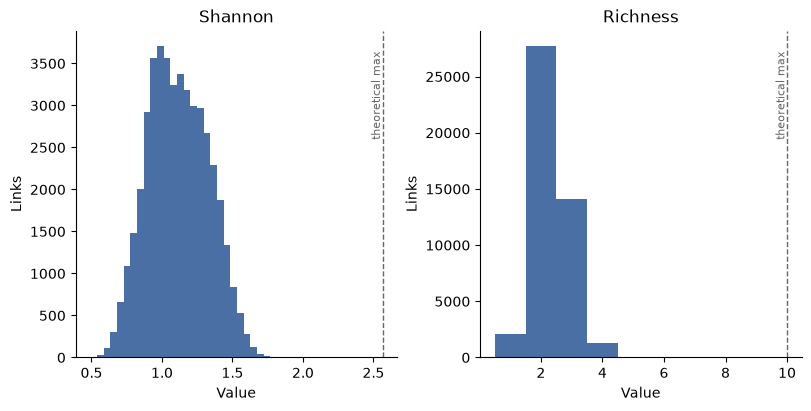

In [18]:
plot_distributions(
    loops,
    measure_columns,
    titles=[TITLES[m] for m in DIVERSITY_MEASURES],
    references=[THEORETICAL_MAX[m] for m in DIVERSITY_MEASURES],
    reference_label="theoretical max",
    integer_columns=["diversity_richness"],
);

for column in measure_columns:
    print(column)
    print(compare_levels(column), end="\n\n")

<br><br>

## 4. Landscape Attractiveness

         links      loops
count  638.000  45218.000
mean     0.229      0.236
std      0.110      0.024
min      0.000      0.036
25%      0.189      0.222
50%      0.224      0.236
75%      0.250      0.250
max      0.833      0.525


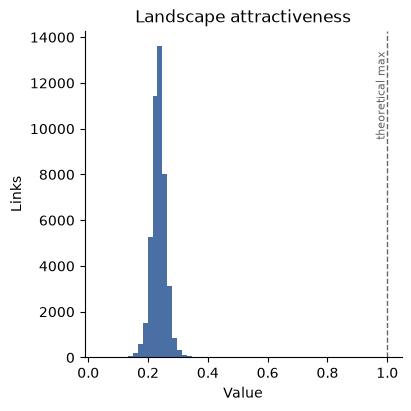

In [19]:
plot_distributions(
    loops,
    ["attractiveness"],
    titles=[TITLES["attractiveness"]],
    references=[1.0],
    reference_label="theoretical max",
);
print(compare_levels("attractiveness"))

<br><br>

## 5. Component Relations

Loops
                    diversity_shannon  diversity_richness  poi_diversity  \
diversity_shannon                1.00                0.62           0.31   
diversity_richness               0.62                1.00           0.19   
poi_diversity                    0.31                0.19           1.00   
attractiveness                   0.14                0.15          -0.09   

                    attractiveness  
diversity_shannon             0.14  
diversity_richness            0.15  
poi_diversity                -0.09  
attractiveness                1.00  

Links
                    diversity_shannon  diversity_richness  poi_diversity  \
diversity_shannon                1.00                0.74           0.33   
diversity_richness               0.74                1.00           0.30   
poi_diversity                    0.33                0.30           1.00   
attractiveness                   0.09               -0.14          -0.15   

                    attractiveness  
div

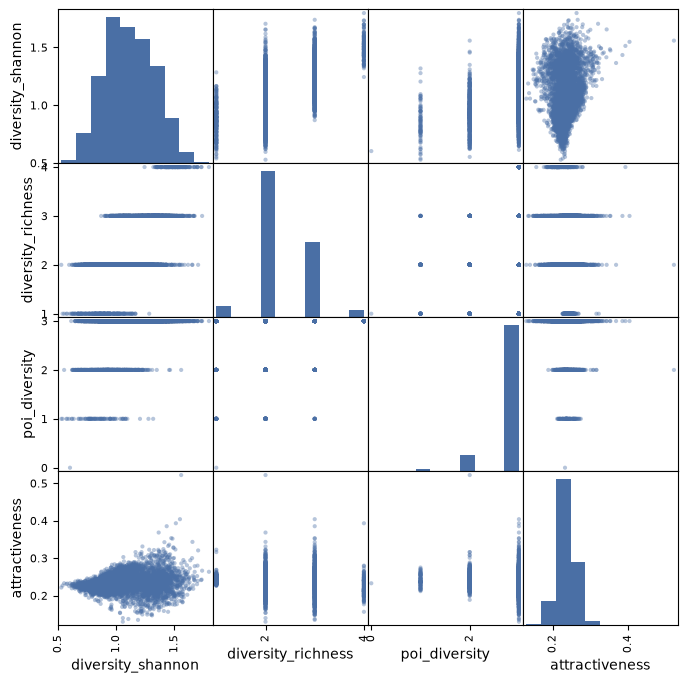

In [20]:
print("Loops")
print(loops[component_columns].corr(method="spearman").round(2), end="\n\n")
print("Links")
print(links[component_columns].corr(method="spearman").round(2))

plot_scatter_matrix(loops_sample, component_columns);

<br><br>

## 6. Length Dependence

                    length_m  n_nodes
diversity_shannon       0.02     0.05
diversity_richness      0.01     0.06
poi_diversity           0.13     0.21
attractiveness         -0.00    -0.05


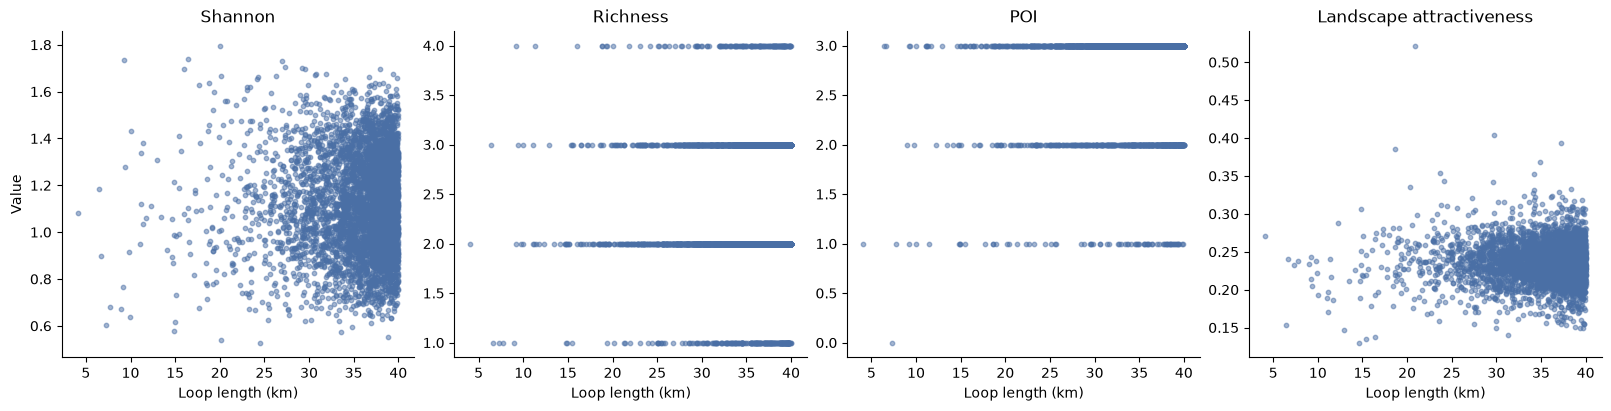

In [21]:
print(loops[["length_m", "n_nodes", *component_columns]].corr(method="spearman")[["length_m", "n_nodes"]].drop(["length_m", "n_nodes"]).round(2))

plot_against(
    loops_sample,
    "length_m",
    component_columns,
    titles=component_titles,
    xlabel="Loop length (km)",
    x_scale_factor=1 / 1000,
);

<br><br>

## 7. Corridor Overlap

count    45218.000
mean         0.905
std          0.010
min          0.782
25%          0.900
50%          0.908
75%          0.913
max          0.933
Name: corridor_ratio, dtype: float64


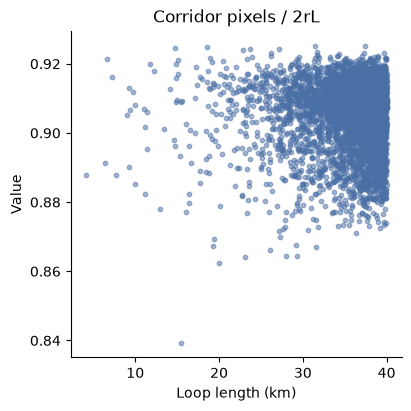

In [22]:
_, transform, _ = load_raster(basemap05_main_types_path(STUDY_AREA))
pixel_area = abs(transform.a * transform.e) # Square meters per pixel

loops["corridor_ratio"] = loops["n_pixels"] * pixel_area / (2 * CORRIDOR_RADIUS * loops["length_m"])
print(loops["corridor_ratio"].describe().round(3))

plot_against(
    loops.loc[loops_sample.index],
    "length_m",
    ["corridor_ratio"],
    titles=["Corridor pixels / 2rL"],
    xlabel="Loop length (km)",
    x_scale_factor=1 / 1000,
);

<br><br>

## 8. Effective Weights

In [23]:
main_columns = [f"diversity_{MAIN_SPECIFICATION['measure']}", "poi_diversity", "attractiveness"]
main_weights = np.array([MAIN_SPECIFICATION[c] for c in ("land_use_weight", "poi_weight", "attractiveness_weight")])

# Share of the score's variance from each component, w_i * cov(x_i, score) / var(score), sums to 1
shares = {}
for normalization in NORMALIZATION_METHODS:
    matrix = np.column_stack([
        normalize_all(
            loops[c].to_numpy(dtype=float), [normalization], *bounds[c], NORMALIZATION_PERCENTILE
        )[normalization]
        for c in main_columns
    ])
    score = matrix @ main_weights
    shares[normalization] = [w * np.cov(matrix[:, i], score)[0, 1] / score.var(ddof=1) for i, w in enumerate(main_weights)]

print(pd.DataFrame(shares, index=["diversity", "POI", "attractiveness"]).T.round(2))

            diversity   POI  attractiveness
bounds           0.59  0.39            0.02
percentile       0.71  0.22            0.07
rank             0.76  0.01            0.22
zscore           0.64  0.20            0.16


<br><br>

## 9. Conclusion

**Loop lengths**

The census is dominated by long loops: the median is 37 km, and three quarters of the loops are longer than 34 km (the bound is 40 km). This follows from how loops are counted (longer loops combine more links, so there are many more of them), and it limits the length range in all the checks below.

**POI**

POI saturates at loop level: 88% of loops have all three categories, 10% two, 1.5% one, and none have zero. Under z-scores, POI is therefore constant for most loops and acts as a penalty for the rest (about −2.3 standard deviations for two categories, −4.9 for one). Whether POI should keep its 0–3 definition at loop level is an open choice.

**Land use diversity**

As expected, loops are more diverse than links and less spread out: median Shannon 1.11 vs 0.80 for links, standard deviation 0.21 vs 0.34. The maximum stays the same (1.91). Richness is mostly 2 or 3.

**Attractiveness**

Attractiveness averages out along loops: the mean is about the same as for links (0.236 vs 0.229), but the spread is much smaller (standard deviation 0.024 vs 0.11, half of the loops between 0.22 and 0.25). Z-scores stretch these small differences to the same spread as the other components, the same effect that was an argument against rank normalization at link level.

**Relations**

The components relate much as they do for links: richness is a coarser version of Shannon (Spearman 0.62), POI is weakly related to land use (0.19–0.31), and attractiveness is nearly unrelated to the rest (−0.09 to 0.15).

**Length**

The components hardly depend on loop length (Spearman ≤ 0.06 for land use and attractiveness), except POI (0.13 with length, 0.21 with the number of nodes). The narrow length range weakens these correlations, so the length bias is small within the census, not necessarily in general.

**Corridor overlap**

Kept pixels make up about 90% of 2r·L for nearly all loops (standard deviation 0.01, minimum 0.78). This is a lower bound on the share without self-overlap, since the own-road exclusion alone removes up to about 10% of the corridor. Self-overlap is therefore small for most loops, and larger only for a few narrow ones.

**Effective weights**

Under z-scores, the variance shares (0.64 / 0.20 / 0.16) are almost the same as for links (0.64 / 0.19 / 0.17), so the stated weights still hold in that sense. But POI's share comes almost entirely from the 12% of loops with fewer than three categories, and attractiveness's share comes from differences that are small in absolute terms. Rank normalization nearly removes POI (0.01) because of the ties.